Using device: cuda
Classes (5): ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Images — train: 2567, validation: 547, test: 556

TRAINING MODEL A (Standard CNN)
ModelA | Epoch [01/50] Train Loss: 1.4086, Train Acc: 0.4616 | Val Loss: 1.1149, Val Acc: 0.5484 | LR: 0.001
ModelA | Epoch [02/50] Train Loss: 1.1486, Train Acc: 0.5294 | Val Loss: 1.0340, Val Acc: 0.5978 | LR: 0.001
ModelA | Epoch [03/50] Train Loss: 1.0400, Train Acc: 0.5859 | Val Loss: 0.9729, Val Acc: 0.6124 | LR: 0.001
ModelA | Epoch [04/50] Train Loss: 1.0207, Train Acc: 0.5949 | Val Loss: 0.9796, Val Acc: 0.5996 | LR: 0.001
ModelA | Epoch [05/50] Train Loss: 0.9601, Train Acc: 0.6213 | Val Loss: 0.8934, Val Acc: 0.6527 | LR: 0.001
ModelA | Epoch [06/50] Train Loss: 0.9377, Train Acc: 0.6369 | Val Loss: 0.8384, Val Acc: 0.6691 | LR: 0.001
ModelA | Epoch [07/50] Train Loss: 0.8677, Train Acc: 0.6716 | Val Loss: 0.8153, Val Acc: 0.7020 | LR: 0.001
ModelA | Epoch [08/50] Train Loss: 0.8498, Train Acc: 0.6751 | Val Los

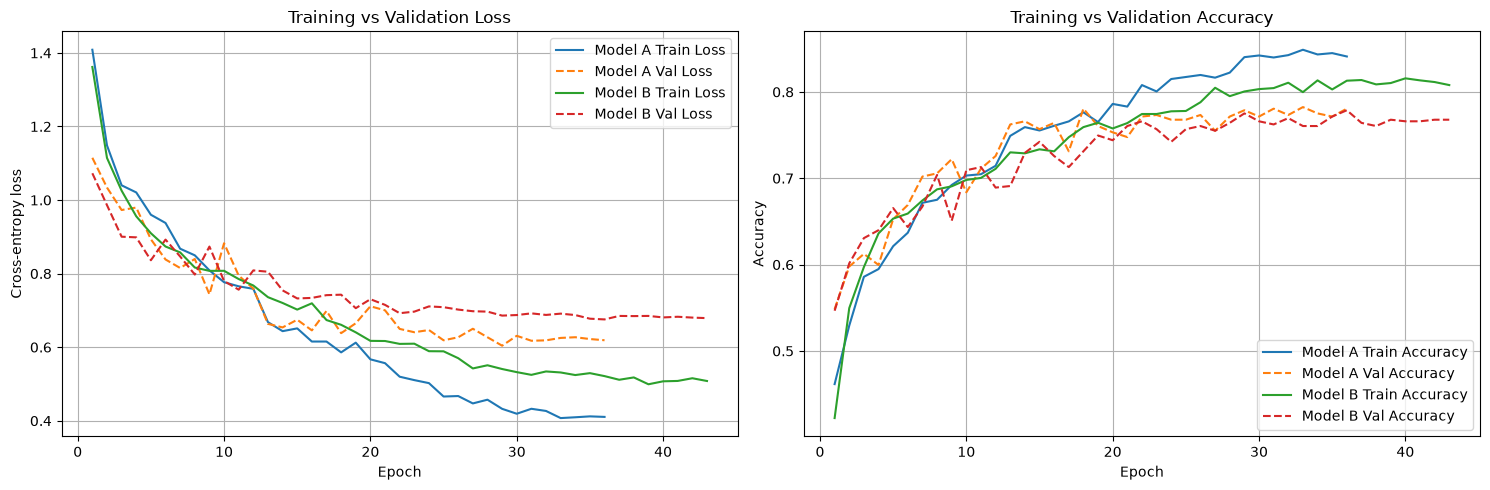

Training curves saved to: d:\Academics\Semester 5\EN3150\Assignments\Assignment 3\CNN-to-perform-classification\results\custom_models_training_curves.png

Metric                           |                     Model A |                     Model B
Trainable parameters             |                   1,143,045 |                      41,413
Model weights size (KB)          |                     4475.70 |                      174.55
Average time per epoch (s)       |                        4.91 |                        6.84
Epochs completed                 |                          36 |                          43
Test accuracy (%)                |                       73.56 |                       70.50
Macro precision (%)              |                       73.37 |                       70.15
Macro recall (%)                 |                       73.16 |                       69.89
Macro F1-score (%)               |                       73.22 |                       69.96
Weighted

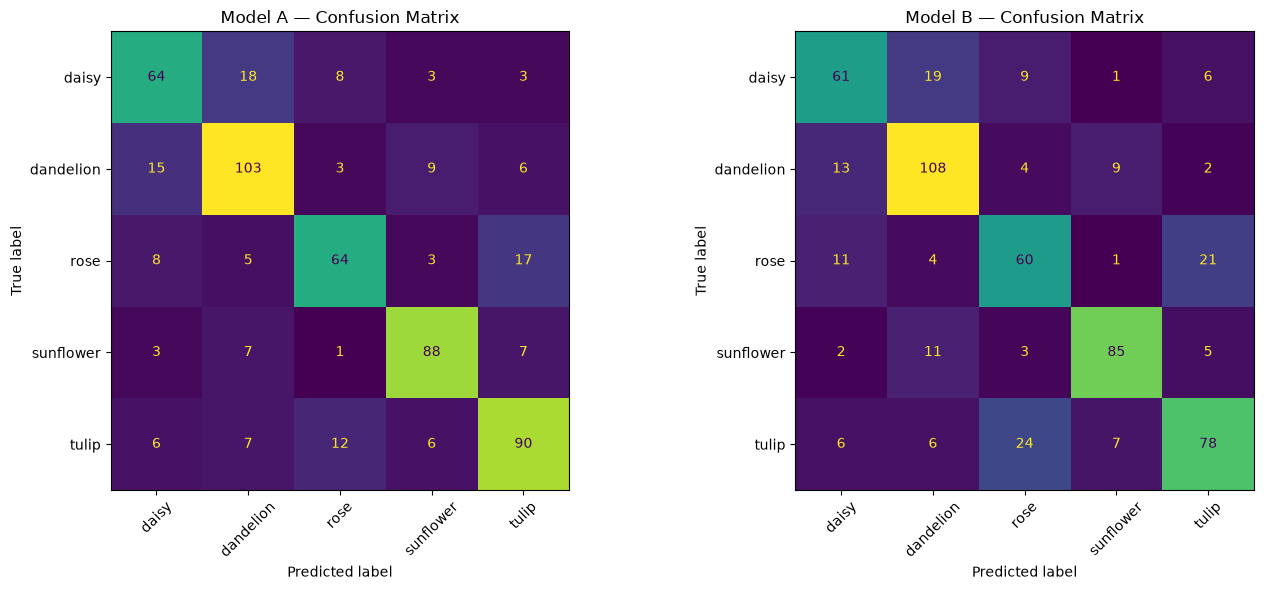

Confusion matrices saved to: d:\Academics\Semester 5\EN3150\Assignments\Assignment 3\CNN-to-perform-classification\results\confusion_matrices.png

Best model weights saved:
  Model A: d:\Academics\Semester 5\EN3150\Assignments\Assignment 3\CNN-to-perform-classification\saved_models\model_a_weights.pth
  Model B: d:\Academics\Semester 5\EN3150\Assignments\Assignment 3\CNN-to-perform-classification\saved_models\model_b_weights.pth
Results directory: d:\Academics\Semester 5\EN3150\Assignments\Assignment 3\CNN-to-perform-classification\results


In [22]:
from pathlib import Path

import os
import sys
import time
import copy
import tempfile

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# ---------------------------------------------------------
# 1. Project paths and imports
# ---------------------------------------------------------
# Assumes this script is run from a directory one level below the project root.
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

TRAIN_DIR = os.path.join(PROJECT_ROOT, "data", "train")
VAL_DIR = os.path.join(PROJECT_ROOT, "data", "val")
TEST_DIR = os.path.join(PROJECT_ROOT, "data", "test")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "results")
WEIGHTS_DIR = os.path.join(PROJECT_ROOT, "saved_models")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR, exist_ok=True)

# ---------------------------------------------------------
# 2. Device and configuration
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 7
NUM_WORKERS = 0  # Reliable default on Windows; increase if appropriate.

# ---------------------------------------------------------
# 3. Data transforms and loaders
# ---------------------------------------------------------
normalization = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    normalization,
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    normalization,
])

for directory in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    if not os.path.isdir(directory):
        raise FileNotFoundError(
            f"Dataset directory not found: {directory}\n"
            "Check PROJECT_ROOT and make sure data/train, data/val, and data/test exist."
        )

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=eval_transform)
test_dataset = datasets.ImageFolder(TEST_DIR, transform=eval_transform)

class_names = train_dataset.classes
num_classes = len(class_names)

if num_classes < 2:
    raise ValueError(f"Expected at least 2 classes, but found {num_classes}: {class_names}")

# ImageFolder assigns class indices alphabetically; all splits must match.
if val_dataset.class_to_idx != train_dataset.class_to_idx:
    raise ValueError(
        "Train and validation class mappings differ.\n"
        f"Train: {train_dataset.class_to_idx}\n"
        f"Val:   {val_dataset.class_to_idx}"
    )
if test_dataset.class_to_idx != train_dataset.class_to_idx:
    raise ValueError(
        "Train and test class mappings differ.\n"
        f"Train: {train_dataset.class_to_idx}\n"
        f"Test:  {test_dataset.class_to_idx}"
    )

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)

print(f"Classes ({num_classes}): {class_names}")
print(
    f"Images — train: {len(train_dataset)}, "
    f"validation: {len(val_dataset)}, test: {len(test_dataset)}"
)

# ---------------------------------------------------------
# 4. Training and validation
# ---------------------------------------------------------
def train_and_validate(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    model_name,
    epochs=EPOCHS,
):
    model = model.to(device)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6
    )

    history = {
        "train_losses": [],
        "val_losses": [],
        "train_accs": [],
        "val_accs": [],
        "learning_rates": [],
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    start_time = time.time()
    epochs_completed = 0

    checkpoint_path = os.path.join(WEIGHTS_DIR, f"{model_name.lower()}_best_weights.pth")

    for epoch in range(epochs):
        epochs_completed += 1

        # Training phase
        model.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)

            if outputs.ndim != 2 or outputs.shape[1] != num_classes:
                raise ValueError(
                    f"{model_name} must output shape [batch, {num_classes}], "
                    f"but got {tuple(outputs.shape)}."
                )

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)
            running_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            train_total += batch_size
            train_correct += (predictions == labels).sum().item()

        epoch_train_loss = running_loss / train_total
        epoch_train_acc = train_correct / train_total

        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                batch_size = labels.size(0)
                val_running_loss += loss.item() * batch_size
                predictions = outputs.argmax(dim=1)
                val_total += batch_size
                val_correct += (predictions == labels).sum().item()

        epoch_val_loss = val_running_loss / val_total
        epoch_val_acc = val_correct / val_total

        history["train_losses"].append(epoch_train_loss)
        history["val_losses"].append(epoch_val_loss)
        history["train_accs"].append(epoch_train_acc)
        history["val_accs"].append(epoch_val_acc)
        history["learning_rates"].append(optimizer.param_groups[0]["lr"])

        scheduler.step(epoch_val_loss)

        print(
            f"{model_name} | Epoch [{epoch + 1:02d}/{epochs:02d}] "
            f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f} | "
            f"LR: {optimizer.param_groups[0]['lr']:.6g}"
        )

        # Keep the weights from the epoch with the lowest validation loss.
        if epoch_val_loss < best_val_loss - 1e-4:
            best_val_loss = epoch_val_loss
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, checkpoint_path)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"{model_name}: early stopping after {epoch + 1} epochs. "
                f"Best validation loss: {best_val_loss:.4f}"
            )
            break

    total_time = time.time() - start_time

    # Restore best validation checkpoint, not the final epoch's weights.
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), checkpoint_path)

    history["avg_epoch_time"] = total_time / epochs_completed
    history["epochs_completed"] = epochs_completed
    history["best_val_loss"] = best_val_loss
    history["checkpoint_path"] = checkpoint_path

    return model, history


# ---------------------------------------------------------
# 5. Test evaluation: accuracy, precision, recall, F1
# ---------------------------------------------------------
def evaluate_test(model, test_loader, class_names):
    model = model.to(device)
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    all_preds = np.asarray(all_preds)
    all_labels = np.asarray(all_labels)

    metrics = {
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision_macro": precision_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            all_labels, all_preds, average="macro", zero_division=0
        ),
        "precision_weighted": precision_score(
            all_labels, all_preds, average="weighted", zero_division=0
        ),
        "recall_weighted": recall_score(
            all_labels, all_preds, average="weighted", zero_division=0
        ),
        "f1_weighted": f1_score(
            all_labels, all_preds, average="weighted", zero_division=0
        ),
    }

    report = classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0,
    )

    return metrics, all_preds, all_labels, report


def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def get_model_disk_size_kb(model, filename):
    torch.save(model.state_dict(), filename)
    size_kb = os.path.getsize(filename) / 1024.0
    os.remove(filename)
    return size_kb


# ---------------------------------------------------------
# 6. Train Model A and Model B
# ---------------------------------------------------------
criterion = nn.CrossEntropyLoss()

print("\n" + "=" * 60)
print("TRAINING MODEL A (Standard CNN)")
print("=" * 60)

model_a = ModelA(num_classes=num_classes)
optimizer_a = optim.Adam(
    model_a.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
model_a, history_a = train_and_validate(
    model_a, train_loader, val_loader, criterion, optimizer_a, "ModelA"
)

print("\n" + "=" * 60)
print("TRAINING MODEL B (Lightweight Depthwise CNN)")
print("=" * 60)

model_b = ModelB(num_classes=num_classes)
optimizer_b = optim.Adam(
    model_b.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
model_b, history_b = train_and_validate(
    model_b, train_loader, val_loader, criterion, optimizer_b, "ModelB"
)

# ---------------------------------------------------------
# 7. Evaluate each best model on the test set ONCE
# ---------------------------------------------------------
metrics_a, preds_a, labels_a, report_a = evaluate_test(model_a, test_loader, class_names)
metrics_b, preds_b, labels_b, report_b = evaluate_test(model_b, test_loader, class_names)

print("\n" + "=" * 60)
print("MODEL A — STANDARD CNN: PER-CLASS TEST METRICS")
print("=" * 60)
print(report_a)

print("\n" + "=" * 60)
print("MODEL B — LIGHTWEIGHT CNN: PER-CLASS TEST METRICS")
print("=" * 60)
print(report_b)

# ---------------------------------------------------------
# 8. Plot training/validation loss and accuracy
# ---------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(15, 5))

epochs_a = range(1, len(history_a["train_losses"]) + 1)
epochs_b = range(1, len(history_b["train_losses"]) + 1)

axs[0].plot(epochs_a, history_a["train_losses"], label="Model A Train Loss")
axs[0].plot(epochs_a, history_a["val_losses"], "--", label="Model A Val Loss")
axs[0].plot(epochs_b, history_b["train_losses"], label="Model B Train Loss")
axs[0].plot(epochs_b, history_b["val_losses"], "--", label="Model B Val Loss")
axs[0].set_title("Training vs Validation Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Cross-entropy loss")
axs[0].legend()
axs[0].grid(True)

axs[1].plot(epochs_a, history_a["train_accs"], label="Model A Train Accuracy")
axs[1].plot(epochs_a, history_a["val_accs"], "--", label="Model A Val Accuracy")
axs[1].plot(epochs_b, history_b["train_accs"], label="Model B Train Accuracy")
axs[1].plot(epochs_b, history_b["val_accs"], "--", label="Model B Val Accuracy")
axs[1].set_title("Training vs Validation Accuracy")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
curves_path = os.path.join(OUTPUT_DIR, "custom_models_training_curves.png")
plt.savefig(curves_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Training curves saved to: {curves_path}")

# ---------------------------------------------------------
# 9. Model comparison table
# ---------------------------------------------------------
params_a = count_trainable_parameters(model_a)
params_b = count_trainable_parameters(model_b)

disk_size_a = get_model_disk_size_kb(
    model_a, os.path.join(WEIGHTS_DIR, "model_a_size_temp.pth")
)
disk_size_b = get_model_disk_size_kb(
    model_b, os.path.join(WEIGHTS_DIR, "model_b_size_temp.pth")
)

comparison_metrics = [
    ("Trainable parameters", params_a, params_b, "integer"),
    ("Model weights size (KB)", disk_size_a, disk_size_b, "float"),
    ("Average time per epoch (s)", history_a["avg_epoch_time"], history_b["avg_epoch_time"], "float"),
    ("Epochs completed", history_a["epochs_completed"], history_b["epochs_completed"], "integer"),
    ("Test accuracy (%)", metrics_a["accuracy"] * 100, metrics_b["accuracy"] * 100, "float"),
    ("Macro precision (%)", metrics_a["precision_macro"] * 100, metrics_b["precision_macro"] * 100, "float"),
    ("Macro recall (%)", metrics_a["recall_macro"] * 100, metrics_b["recall_macro"] * 100, "float"),
    ("Macro F1-score (%)", metrics_a["f1_macro"] * 100, metrics_b["f1_macro"] * 100, "float"),
    ("Weighted precision (%)", metrics_a["precision_weighted"] * 100, metrics_b["precision_weighted"] * 100, "float"),
    ("Weighted recall (%)", metrics_a["recall_weighted"] * 100, metrics_b["recall_weighted"] * 100, "float"),
    ("Weighted F1-score (%)", metrics_a["f1_weighted"] * 100, metrics_b["f1_weighted"] * 100, "float"),
]

print("\n" + "=" * 94)
print(f"{'Metric':<32} | {'Model A':>27} | {'Model B':>27}")
print("=" * 94)
for name, value_a, value_b, value_type in comparison_metrics:
    if value_type == "integer":
        print(f"{name:<32} | {value_a:>27,} | {value_b:>27,}")
    else:
        print(f"{name:<32} | {value_a:>27.2f} | {value_b:>27.2f}")
print("=" * 94)

# ---------------------------------------------------------
# 10. Confusion matrices
# ---------------------------------------------------------
fig, axs = plt.subplots(1, 2, figsize=(14, 6))

cm_a = confusion_matrix(labels_a, preds_a, labels=list(range(num_classes)))
cm_b = confusion_matrix(labels_b, preds_b, labels=list(range(num_classes)))

ConfusionMatrixDisplay(
    confusion_matrix=cm_a, display_labels=class_names
).plot(ax=axs[0], values_format="d", colorbar=False)
axs[0].set_title("Model A — Confusion Matrix")
axs[0].tick_params(axis="x", rotation=45)

ConfusionMatrixDisplay(
    confusion_matrix=cm_b, display_labels=class_names
).plot(ax=axs[1], values_format="d", colorbar=False)
axs[1].set_title("Model B — Confusion Matrix")
axs[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
confusion_path = os.path.join(OUTPUT_DIR, "confusion_matrices.png")
plt.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Confusion matrices saved to: {confusion_path}")

# ---------------------------------------------------------
# 11. Save final best-validation model weights
# ---------------------------------------------------------
final_a_path = os.path.join(WEIGHTS_DIR, "model_a_weights.pth")
final_b_path = os.path.join(WEIGHTS_DIR, "model_b_weights.pth")
torch.save(model_a.state_dict(), final_a_path)
torch.save(model_b.state_dict(), final_b_path)

print("\nBest model weights saved:")
print(f"  Model A: {final_a_path}")
print(f"  Model B: {final_b_path}")
print(f"Results directory: {OUTPUT_DIR}")


In [ ]:
import os
import sys
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Path resolution so models can be imported from any location
CURRENT_DIR = os.path.dirname(os.path.abspath(__file__)) if "__file__" in locals() else os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(CURRENT_DIR, ".."))

if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from models.model_a import ModelA
from models.model_b import ModelB

def generate_class_template(model, target_class_idx, steps=300, lr=0.05, device='cpu'):
    """
    Performs Gradient Ascent starting from random noise to generate an image
    that maximally activates a target class in the given model.
    """
    model.eval()
    model.to(device)

    # Start with random noise image (1, 3, 64, 64)
    input_img = torch.randn(1, 3, 64, 64, device=device, requires_grad=True)
    optimizer = torch.optim.Adam([input_img], lr=lr)

    for step in range(steps):
        optimizer.zero_grad()
        output = model(input_img)
        
        # Loss is negative logits for the target class (gradient ascent minimizes this)
        loss = -output[0, target_class_idx]
        loss.backward()
        optimizer.step()

    # Post-process tensor back to RGB viewable image [0, 1]
    img = input_img.squeeze(0).detach().cpu().numpy()
    img = np.transpose(img, (1, 2, 0))
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)  # Normalize
    return img

def show_both_models_class_templates(model_a, model_b, class_names=['daisy', 'dandelion', 'rose', 'sunflower', 'tulip'], device='cpu'):
    """
    Generates and plots class activation templates for Model A and Model B side-by-side.
    """
    fig, axs = plt.subplots(2, 5, figsize=(15, 6))

    print("Generating class activation templates for Model A...")
    for idx, name in enumerate(class_names):
        template_a = generate_class_template(model_a, target_class_idx=idx, device=device)
        axs[0, idx].imshow(template_a)
        axs[0, idx].set_title(f"Model A: {name}")
        axs[0, idx].axis('off')

    print("Generating class activation templates for Model B...")
    for idx, name in enumerate(class_names):
        template_b = generate_class_template(model_b, target_class_idx=idx, device=device)
        axs[1, idx].imshow(template_b)
        axs[1, idx].set_title(f"Model B: {name}")
        axs[1, idx].axis('off')

    plt.suptitle("Class Activation Patterns (Gradient Ascent in Input Space)", fontsize=14)
    plt.tight_layout()
    plt.savefig('class_activation_templates.png')
    plt.show()

# --- Execution Block ---
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Instantiate models
    model_a = ModelA(num_classes=5)
    model_b = ModelB(num_classes=5)

    # 2. Locate saved weight files
    weights_a_path = os.path.join(PROJECT_ROOT, "saved_models", "model_a_weights.pth")
    weights_b_path = os.path.join(PROJECT_ROOT, "saved_models", "model_b_weights.pth")

    # 3. Load saved weights
    if os.path.exists(weights_a_path):
        model_a.load_state_dict(torch.load(weights_a_path, map_location=device))
        print("Loaded Model A weights successfully.")
    else:
        print(f"Warning: Model A weights not found at '{weights_a_path}'. Using untrained weights.")

    if os.path.exists(weights_b_path):
        model_b.load_state_dict(torch.load(weights_b_path, map_location=device))
        print("Loaded Model B weights successfully.")
    else:
        print(f"Warning: Model B weights not found at '{weights_b_path}'. Using untrained weights.")

    # 4. Generate and display templates
    show_both_models_class_templates(model_a, model_b, device=device)

Loaded Model A weights successfully.
Loaded Model B weights successfully.
Generating class activation templates for Model A...
Generating class activation templates for Model B...
